# Лабораторная 1. Биологический ответ молекул

Maksim Kostromitin  
Group: J4132


In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.tree import DecisionTreeClassifier

SEED = 42
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 120, "font.size": 11})

## Данные

`Activity` — целевой класс: 1 означает биологический ответ, 0 — его отсутствие. Столбцы `D1`, `D2` и далее — числовые характеристики молекулы.

In [2]:
data = pd.read_csv("bioresponse.csv")
display(data.iloc[:5, :7])

,Activity,D1,D2,D3,D4,D5,D6
0,1,0.0000,0.4970,0.10,0.0,0.1330,0.6780
1,1,0.3667,0.6063,0.05,0.0,0.1112,0.8035
2,1,0.0333,0.4801,0.00,0.0,0.2098,0.6104
3,1,0.0000,0.5388,0.00,0.5,0.1963,0.7242
4,0,0.1000,0.5178,0.00,0.0,0.4947,0.7814


In [3]:
X = data.drop(columns="Activity")
y = data["Activity"]
display(y.value_counts().sort_index().rename_axis("Класс").to_frame("Молекул"))

,Молекул
Класс,
0,1717
1,2034


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)

split_info = pd.DataFrame(
    {
        "Объектов": [len(y_train), len(y_test)],
        "Класс 0": [(y_train == 0).sum(), (y_test == 0).sum()],
        "Класс 1": [(y_train == 1).sum(), (y_test == 1).sum()],
        "Доля класса 1": [y_train.mean(), y_test.mean()],
    },
    index=["Обучающая выборка", "Тестовая выборка"],
)
display(split_info)

,Объектов,Класс 0,Класс 1,Доля класса 1
Обучающая выборка,2813,1288,1525,0.5421
Тестовая выборка,938,429,509,0.5426


## Деревья и случайные леса

Неглубокие деревья ограничены глубиной 3, глубокие — без ограничения. В каждом лесу по 300 деревьев.

Точность положительных прогнозов (`precision`) — доля действительно активных молекул среди тех, которые модель назвала активными. Полнота (`recall`) — доля найденных активных молекул. F1 — среднее гармоническое точности и полноты.

Доля верных ответов (`accuracy`) учитывает оба класса. Логарифмические потери (`log-loss`) оценивают предсказанные вероятности и особенно сильно штрафуют уверенные ошибки; чем они меньше, тем лучше.

In [5]:
def get_metrics(y_true, y_pred, y_prob):
    return {
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred),
        "accuracy": accuracy_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "log-loss": log_loss(y_true, y_prob),
    }

metric_labels = {
    "precision": "Точность",
    "recall": "Полнота",
    "accuracy": "Доля верных ответов",
    "log-loss": "Логарифмические потери",
}

In [6]:
models = {
    "Дерево, глубина 3": DecisionTreeClassifier(max_depth=3, random_state=SEED),
    "Глубокое дерево": DecisionTreeClassifier(max_depth=None, random_state=SEED),
    "Лес, глубина 3": RandomForestClassifier(
        n_estimators=300, max_depth=3, random_state=SEED, n_jobs=2
    ),
    "Глубокий лес": RandomForestClassifier(
        n_estimators=300, max_depth=None, random_state=SEED, n_jobs=2
    ),
}

scores = {}
test_prob = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    probability = model.predict_proba(X_test)[:, 1]
    scores[name] = get_metrics(y_test, predictions, probability)
    test_prob[name] = probability

display(pd.DataFrame.from_dict(scores, orient="index").rename(columns=metric_labels).round(4))

,Точность,Полнота,Доля верных ответов,F1,Логарифмические потери
"Дерево, глубина 3",0.7539,0.7525,0.7324,0.7532,0.7238
Глубокое дерево,0.7169,0.7662,0.7090,0.7407,10.4903
"Лес, глубина 3",0.7077,0.7564,0.6983,0.7312,0.6042
Глубокий лес,0.7871,0.8134,0.7793,0.8000,0.4734


Глубокий лес дал наибольшую долю верных ответов и лучший F1. У глубокого дерева особенно велики логарифмические потери. В чистых листьях оно присваивает классу вероятность 0 или 1, и каждая уверенная ошибка дорого обходится.

### Подбор порога для высокой полноты

При обучении вес активных молекул равен 3, остальных — 1. Для выбора порога использую перекрёстную проверку: обучающую выборку делю на пять частей и для каждой получаю прогноз модели, обученной на остальных четырёх.

Среди порогов с полнотой не ниже 0,98 выбираю тот, который даёт наибольшую точность положительных прогнозов.

In [7]:
fn_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    class_weight={0: 1, 1: 3},
    random_state=SEED,
    n_jobs=2,
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

oof_prob = cross_val_predict(
    fn_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=1
)[:, 1]

In [8]:
precision, recall, thresholds = precision_recall_curve(y_train, oof_prob)
threshold_scores = pd.DataFrame(
    {
        "threshold": thresholds,
        "precision": precision[:-1],
        "recall": recall[:-1],
    }
)

target_recall = 0.98
candidates = threshold_scores[threshold_scores["recall"] >= target_recall]
chosen = candidates.sort_values(["precision", "threshold"], ascending=False).iloc[0]
threshold = float(chosen["threshold"])
display(chosen.rename(index={
    "threshold": "Порог", "precision": "Точность", "recall": "Полнота",
}).to_frame("Перекрёстная проверка"))

,Перекрёстная проверка
Порог,0.2589
Точность,0.6206
Полнота,0.9803


In [9]:
fn_model.fit(X_train, y_train)
fn_prob = fn_model.predict_proba(X_test)[:, 1]
default_pred = (fn_prob >= 0.5).astype(int)
fn_pred = (fn_prob >= threshold).astype(int)
comparison = {
    "Порог 0.5": get_metrics(y_test, default_pred, fn_prob),
    "Выбранный порог": get_metrics(y_test, fn_pred, fn_prob),
}
display(pd.DataFrame.from_dict(comparison, orient="index").rename(columns=metric_labels).round(4))

,Точность,Полнота,Доля верных ответов,F1,Логарифмические потери
Порог 0.5,0.7589,0.8409,0.7687,0.7978,0.4812
Выбранный порог,0.6163,0.9784,0.6578,0.7563,0.4812


## Кривые точности–полноты и ROC

Первая кривая показывает, как меняется точность положительных прогнозов при увеличении полноты. Средняя точность (AP) обобщает качество этой кривой: чем ближе к 1, тем лучше.

ROC-кривая показывает полноту при разных долях ложных срабатываний среди неактивных молекул. AUC — площадь под ROC-кривой; чем ближе к 1, тем лучше.

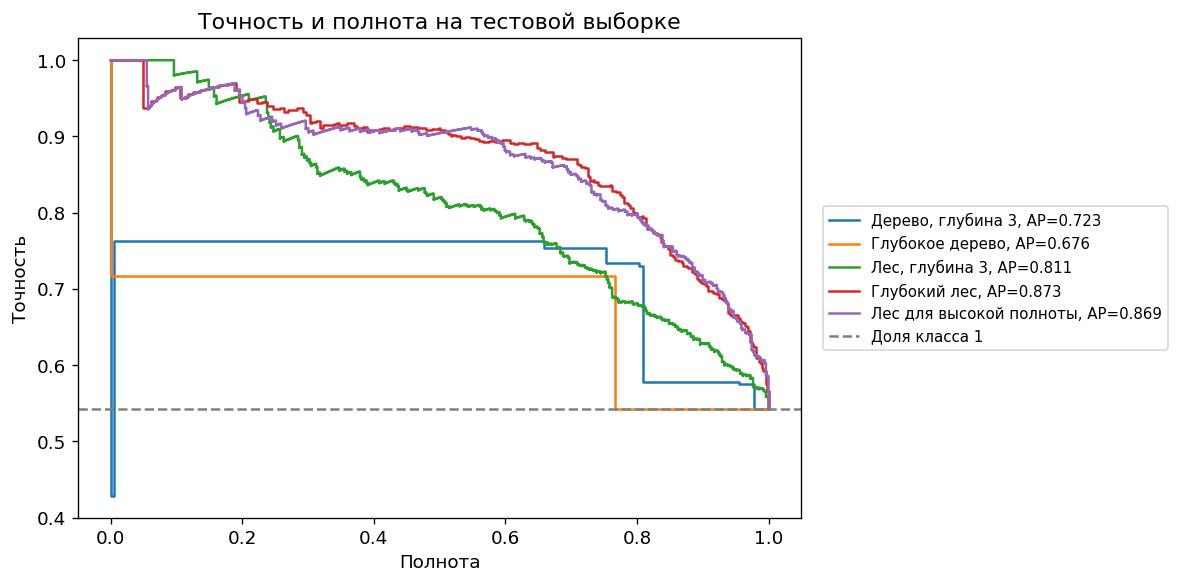

In [10]:
curve_prob = test_prob.copy()
curve_prob["Лес для высокой полноты"] = fn_prob
fig, ax = plt.subplots(figsize=(10, 5))
for name, prob in curve_prob.items():
    precision, recall, _ = precision_recall_curve(y_test, prob)
    ap = average_precision_score(y_test, prob)
    ax.step(recall, precision, where="post", label=f"{name}, AP={ap:.3f}")
ax.axhline(y_test.mean(), linestyle="--", color="gray", label="Доля класса 1")
ax.set(xlabel="Полнота", ylabel="Точность", title="Точность и полнота на тестовой выборке")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=9)
plt.tight_layout()
plt.show()

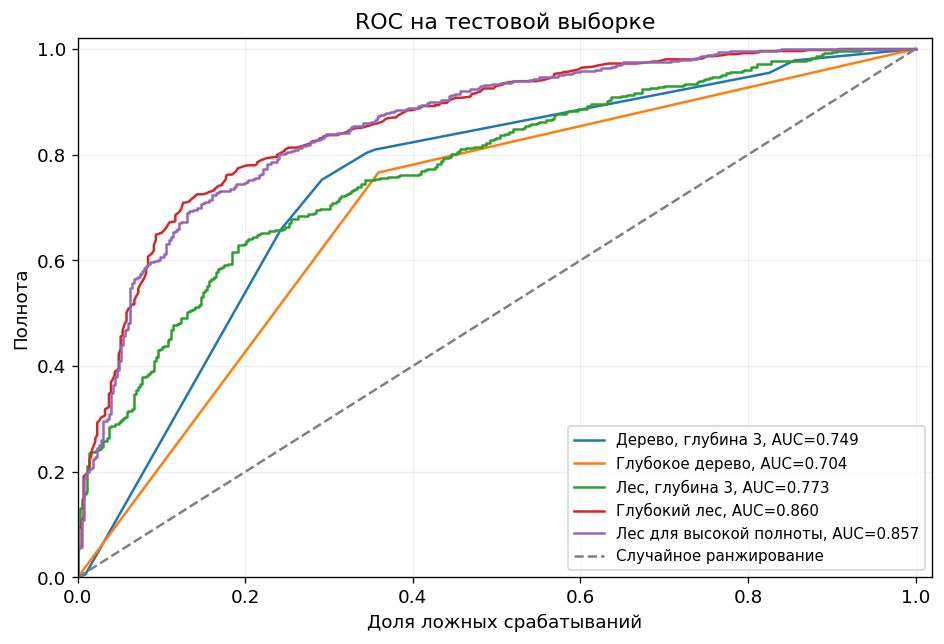

In [11]:
fig, ax = plt.subplots(figsize=(8, 5.5))
for name, prob in curve_prob.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    ax.plot(fpr, tpr, label=f"{name}, AUC={auc:.3f}")

ax.plot([0, 1], [0, 1], "--", color="gray", label="Случайное ранжирование")
ax.set(
    xlabel="Доля ложных срабатываний",
    ylabel="Полнота",
    xlim=(0, 1.02),
    ylim=(0, 1.02),
)
ax.set_title("ROC на тестовой выборке")
ax.grid(alpha=0.2)
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

## Ошибки II рода

Ошибка II рода (FN) — пропущенная активная молекула; FP — ложное срабатывание. TP и TN обозначают верные ответы для активных и неактивных молекул соответственно.

Сравним один и тот же лес при пороге 0,5 и при выбранном пороге.

In [12]:
errors = {}
for label, predictions in [("Порог 0.5", default_pred), ("Выбранный порог", fn_pred)]:
    tn, fp, fn, tp = confusion_matrix(y_test, predictions).ravel()
    errors[label] = {"TN": tn, "FP": fp, "FN": fn, "TP": tp}
display(pd.DataFrame.from_dict(errors, orient="index").rename(columns={
    "TN": "Верно неактивные", "FP": "Ложные срабатывания",
    "FN": "Пропуски активных", "TP": "Верно активные",
}))

,Верно неактивные,Ложные срабатывания,Пропуски активных,Верно активные
Порог 0.5,293,136,81,428
Выбранный порог,119,310,11,498


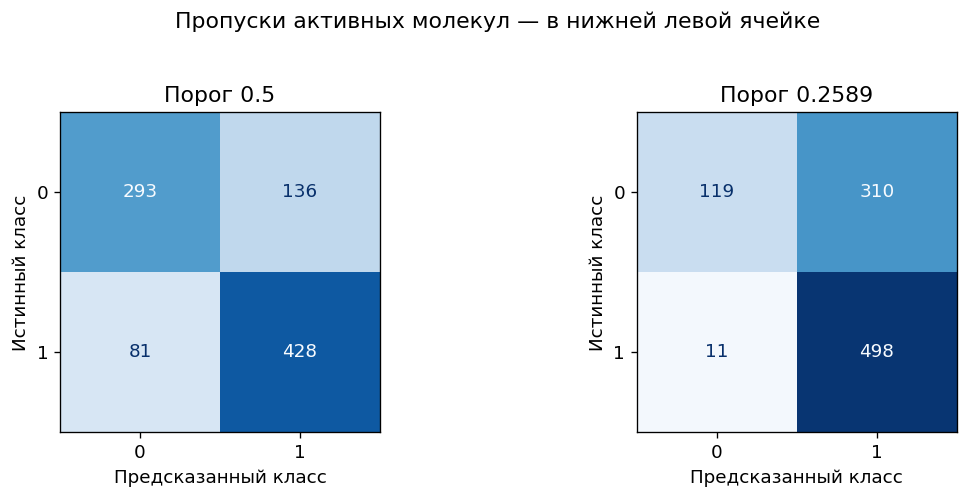

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, pred, title in zip(
    axes, [default_pred, fn_pred], ["Порог 0.5", f"Порог {threshold:.4f}"]
):
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["0", "1"]).plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d",
        im_kw={"vmin": 0, "vmax": int((y_test == 1).sum())},
    )
    ax.set_title(title)
    ax.set_xlabel("Предсказанный класс")
    ax.set_ylabel("Истинный класс")
fig.suptitle("Пропуски активных молекул — в нижней левой ячейке", y=1.03)
plt.tight_layout()
plt.show()

## Выводы

Глубокий лес дал наибольшую долю верных ответов и лучший F1. После снижения порога полнота достигла 97,84%, а число пропущенных активных молекул снизилось с 81 до 11. Ложных срабатываний при этом стало больше: 310 вместо 136.